<a href="https://colab.research.google.com/github/sandyyshores/gen-ai/blob/main/Week2_Gemini_MongoDB_Logging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install -q -U google-genai pymongo pandas matplotlib

In [10]:
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")


Gemini API key configured successfully!


In [11]:
from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        timeout=30000
    )
)

MODEL_NAME = "gemini-3.8-flash"

print("Gemini client initialized successfully!")


Gemini client initialized successfully!


In [12]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [24]:
MONGODB_URI = userdata.get("MONGODB_URI")

if not MONGODB_URI:
    raise ValueError("MongoDB connection string is missing!")

print("MongoDB credentials loaded successfully!")


MongoDB credentials loaded successfully!


In [25]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=5000,
    connectTimeoutMS=5000,
    socketTimeoutMS=10000,
    timeoutMS=10000,
    retryWrites=True
)

# Test the database connection
mongo_client.admin.command("ping")

# Create database
db = mongo_client["GenAI_Monitoring"]

# Create collection
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)



MongoDB connected successfully!
Database: GenAI_Monitoring
Collection: api_usage_logs


In [26]:
import time
import uuid
import random
import pymongo

from datetime import datetime, timezone
from pymongo.errors import PyMongoError


In [28]:
# Gemini 2.5 Flash standard paid-tier pricing
# USD per 1 million tokens

INPUT_PRICE = 0.30
OUTPUT_PRICE = 2.50

def calculate_cost(input_tokens, output_tokens):

    input_cost = (
        input_tokens * INPUT_PRICE / 1_000_000
    )

    output_cost = (
        output_tokens * OUTPUT_PRICE / 1_000_000
    )

    total_cost = input_cost + output_cost

    return total_cost


In [29]:
input_tokens = 1000
output_tokens = 2000

cost = calculate_cost(
    input_tokens,
    output_tokens
)

print("Estimated cost: $", cost)


Estimated cost: $ 0.0053


In [31]:
def retry_delay(attempt):

    delay = min(2 ** (attempt - 1), 16)

    return delay + random.uniform(0, 1)


def is_temporary_error(error):

    status_code = getattr(
        error, "status_code",
        getattr(error, "code", None)
    )

    if status_code in [408, 429, 500, 502, 503, 504]:
        return True

    error_name = type(error).__name__.lower()

    temporary_errors = [
        "timeout",
        "connection",
        "temporarily"
    ]

    return any(
        word in error_name
        for word in temporary_errors
    )


In [32]:
def save_log(record):

    for attempt in range(1, 4):

        try:

            with pymongo.timeout(10):

                collection.update_one(
                    {"_id": record["_id"]},
                    {"$setOnInsert": record},
                    upsert=True
                )

            print("Log saved in MongoDB!")
            return True

        except PyMongoError as error:

            print(
                f"MongoDB error: {error}"
            )

            if attempt == 3:
                print("Unable to save the log.")
                return False

            time.sleep(retry_delay(attempt))

    return False


In [33]:
def ask_gemini(prompt):
    request_id = str(uuid.uuid4())
    MAX_RETRIES = 4

    for attempt in range(1, MAX_RETRIES + 1):
        start_time = time.perf_counter()

        input_tokens = 0
        output_tokens = 0
        total_tokens = 0
        response_text = ""
        error = None
        error_message = None
        status = "failed"

        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt
            )

            response_text = response.text or ""

            usage = response.usage_metadata

            if usage:
                input_tokens = usage.prompt_token_count or 0
                output_tokens = usage.candidates_token_count or 0
                total_tokens = usage.total_token_count or 0

            status = "success"

        except Exception as e:
            error = e
            error_message = str(e)
            print(f"API attempt {attempt} failed: {error_message}")

        latency = time.perf_counter() - start_time

        estimated_cost = calculate_cost(input_tokens, output_tokens)

        log_record = {
            "_id": f"{request_id}_{attempt}",
            "request_id": request_id,
            "timestamp": datetime.now(timezone.utc),
            "model": MODEL_NAME,
            "prompt": prompt,
            "attempt": attempt,
            "input_tokens": input_tokens,
            "output_tokens": output_tokens,
            "total_tokens": total_tokens,
            "latency_seconds": round(latency, 3),
            "estimated_cost_usd": round(estimated_cost, 10),
            "status": status,
            "error": error_message
        }

        save_log(log_record)

        print("\n========== API MONITORING ==========")
        print("Request ID:", request_id)
        print("Attempt:", attempt)
        print("Status:", status)
        print("Input Tokens:", input_tokens)
        print("Output Tokens:", output_tokens)
        print("Total Tokens:", total_tokens)
        print("Latency:", round(latency, 3), "seconds")
        print("Estimated Cost: $", estimated_cost)

        if status == "success":
            print("\n========== GEMINI RESPONSE ==========")
            print(response_text)
            return response_text

        if attempt == MAX_RETRIES or not is_temporary_error(error):
            print("\nRequest failed permanently.")
            break

        wait_time = retry_delay(attempt)
        print(f"Retrying after {wait_time:.2f} seconds...")
        time.sleep(wait_time)

    return None

In [42]:
while True:

    prompt = input("\nEnter your question (or type exit): ")

    if prompt.lower() == "exit":
        print("Application stopped.")
        break

    if not prompt.strip():
        print("Please enter a valid question.")
        continue

    ask_gemini(prompt)



Enter your question (or type exit): What is 1+1 ?
API attempt 1 failed: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}
Log saved in MongoDB!

========== API MONITORING ==========
Request ID: bb63ef39-dd40-4885-89ab-a7a8812fa393
Attempt: 1
Status: failed
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 28.208 seconds
Estimated Cost: $ 0.0
Retrying after 1.10 seconds...
Log saved in MongoDB!

========== API MONITORING ==========
Request ID: bb63ef39-dd40-4885-89ab-a7a8812fa393
Attempt: 2
Status: success
Input Tokens: 8
Output Tokens: 7
Total Tokens: 92
Latency: 2.14 seconds
Estimated Cost: $ 1.99e-05

========== GEMINI RESPONSE ==========
1 + 1 = 2

Enter your question (or type exit): Explain what is python
API attempt 1 failed: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}
Log saved in M

In [44]:
records = list(
    collection.find(
        {},
        {"_id": 0}
    ).sort("timestamp", -1)
)

print("Total API attempts:", len(records))

for record in records:

    print("\n--------------------------")

    print("Model:", record["model"])

    print("Input Tokens:", record["input_tokens"])

    print("Output Tokens:", record["output_tokens"])

    print("Total Tokens:", record["total_tokens"])

    print("Latency:", record["latency_seconds"])

    print("Cost:", record["estimated_cost_usd"])

    print("Status:", record["status"])


Total API attempts: 11

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 1.553
Cost: 0.0
Status: failed

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 28.05
Cost: 0.0
Status: failed

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 28.034
Cost: 0.0
Status: failed

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 1.434
Cost: 0.0
Status: failed

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 28.002
Cost: 0.0
Status: failed

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 28.231
Cost: 0.0
Status: failed

--------------------------
Model: gemini-3.8-flash
Input Tokens: 0
Output Tokens: 0
Total Tokens: 0
Latency: 28.216
Cost: 0.0
S

In [45]:
import pandas as pd

records = list(
    collection.find({}, {"_id": 0})
)

df = pd.DataFrame(records)

if not df.empty:

    display(df)

else:

    print("No records found.")


,attempt,error,estimated_cost_usd,input_tokens,latency_seconds,model,output_tokens,prompt,request_id,status,timestamp,total_tokens
0,1,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.067,gemini-3.8-flash,0,What is python >,c1dc5a3e-2362-4238-ba09-aebf4c450655,failed,2026-11-13 05:06:34.912,0
1,1,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.208,gemini-3.8-flash,0,What is 1+1 ?,bb63ef39-dd40-4885-89ab-a7a8812fa393,failed,2026-11-13 05:13:17.615,0
2,2,NaN,0.00002,8,2.140,gemini-3.8-flash,7,What is 1+1 ?,bb63ef39-dd40-4885-89ab-a7a8812fa393,success,2026-11-13 05:13:21.111,92
3,1,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.234,gemini-3.8-flash,0,Explain what is python,00b63762-492c-4a92-9500-857fb9ca30d0,failed,2026-11-13 05:14:25.304,0
4,2,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.216,gemini-3.8-flash,0,Explain what is python,00b63762-492c-4a92-9500-857fb9ca30d0,failed,2026-11-13 05:14:54.781,0
5,3,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.231,gemini-3.8-flash,0,Explain what is python,00b63762-492c-4a92-9500-857fb9ca30d0,failed,2026-11-13 05:15:25.757,0
6,4,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.002,gemini-3.8-flash,0,Explain what is python,00b63762-492c-4a92-9500-857fb9ca30d0,failed,2026-11-13 05:15:58.655,0
7,1,"503 UNAVAILABLE. {'error': {'code': 503, 'mess...",0.00000,0,1.434,gemini-3.8-flash,0,Explain Generative AI?,cc7002ef-4e88-40d3-8733-86377761b6d0,failed,2026-11-13 05:16:15.544,0
8,2,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.034,gemini-3.8-flash,0,Explain Generative AI?,cc7002ef-4e88-40d3-8733-86377761b6d0,failed,2026-11-13 05:16:45.161,0
9,3,"504 DEADLINE_EXCEEDED. {'error': {'code': 504,...",0.00000,0,28.050,gemini-3.8-flash,0,Explain Generative AI?,cc7002ef-4e88-40d3-8733-86377761b6d0,failed,2026-11-13 05:17:16.201,0


In [46]:
pipeline = [
    {
        "$group": {
            "_id": None,
            "total_api_attempts": {"$sum": 1},
            "total_input_tokens": {"$sum": "$input_tokens"},
            "total_output_tokens": {"$sum": "$output_tokens"},
            "total_tokens": {"$sum": "$total_tokens"},
            "average_latency": {"$avg": "$latency_seconds"},
            "total_estimated_cost": {"$sum": "$estimated_cost_usd"}
        }
    }
]

result = list(collection.aggregate(pipeline))

if result:
    summary = result[0]
    print("Total API Attempts:", summary["total_api_attempts"])
    print("Total Input Tokens:", summary["total_input_tokens"])
    print("Total Output Tokens:", summary["total_output_tokens"])
    print("Total Tokens:", summary["total_tokens"])
    print("Average Latency:", round(summary["average_latency"], 3))
    print("Total Estimated Cost: $", summary["total_estimated_cost"])
else:
    print("No API usage data available.")

Total API Attempts: 11
Total Input Tokens: 8
Total Output Tokens: 7
Total Tokens: 92
Average Latency: 20.924
Total Estimated Cost: $ 1.99e-05


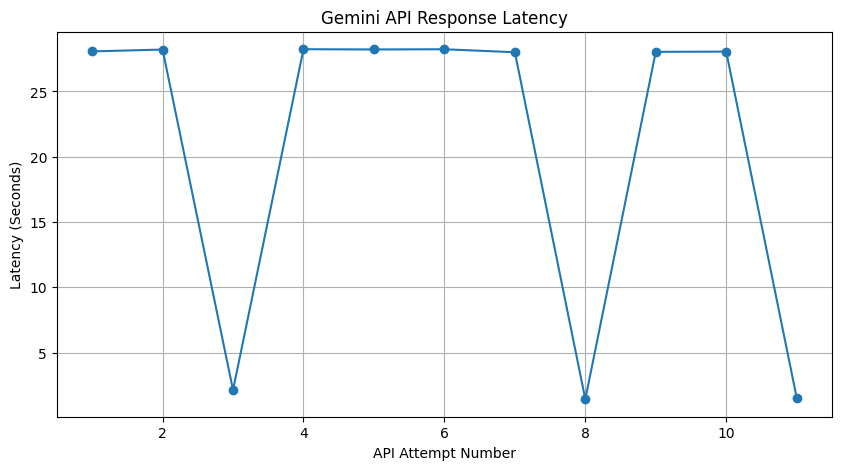

In [47]:
import matplotlib.pyplot as plt

if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.plot(
        range(1, len(df) + 1),
        df["latency_seconds"],
        marker="o"
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Latency (Seconds)")

    plt.title("Gemini API Response Latency")

    plt.grid(True)

    plt.show()


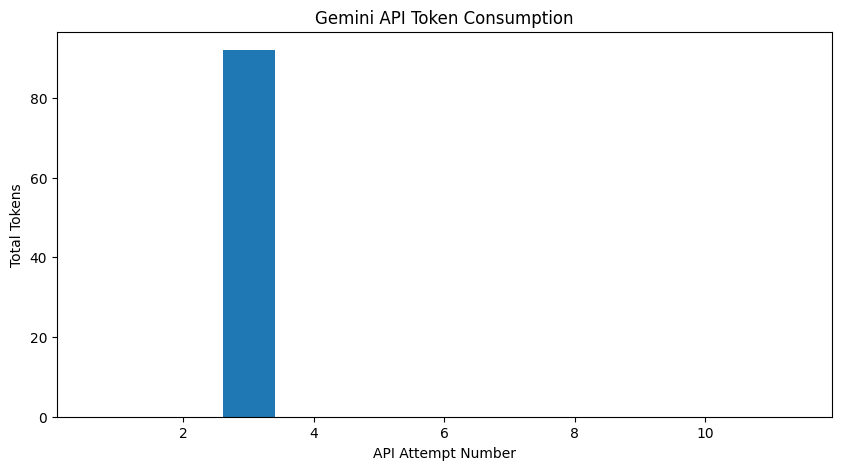

In [48]:
if not df.empty:

    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["total_tokens"]
    )

    plt.xlabel("API Attempt Number")

    plt.ylabel("Total Tokens")

    plt.title("Gemini API Token Consumption")

    plt.show()
